# **AE Complex 1 latent: ampliando el cuello de botella a 256 dimensiones**

## **0. Introducción y objetivo**

En este notebook continuamos el estudio iniciado en `AE_complex1`. Allí construimos un autoencoder convolucional con un espacio latente de `128` dimensiones y obtuvimos un FID de reconstrucción de `72.94` sobre `test`. Ahora nos preguntamos si ese resultado está limitado por la dimensión del latente, es decir, si el **cuello de botella** es realmente un problema.

Para responderlo mantenemos la misma arquitectura convolucional, la misma resolución RGB de `64x64`, las mismas particiones y la misma función de pérdida, y cambiamos únicamente la dimensión latente de `128` a `256`. De este modo podemos atribuir la mejora (o su ausencia) principalmente a esa decisión, en lugar de a un cambio de arquitectura.

Recordamos que un **autoencoder** está formado por un **encoder**, que comprime cada imagen en un vector latente, y un **decoder**, que intenta recuperarla. El *morphing* se hará interpolando entre vectores latentes y decodificando los puntos intermedios, no mezclando píxeles directamente.

Igual que en el notebook anterior, trabajamos de forma **determinista en la medida permitida por el entorno**: fijamos las semillas, usamos las particiones guardadas y seleccionamos siempre los mismos ejemplos. Por defecto `TRAIN_MODEL = False`, de modo que cargamos los modelos y el historial ya calculados desde `autoencoders/checkpoints/`. Si queremos repetir el entrenamiento, cambiamos ese parámetro a `True`.

El recorrido será: cargar los datos, definir la arquitectura, justificar la pérdida, entrenar o cargar el modelo, evaluar reconstrucciones, medir el FID y generar una secuencia y un GIF de morphing.

---

## **1. Configuración e imports**

Importamos las bibliotecas de visualización, tratamiento de imágenes, TensorFlow y TorchMetrics. Las rutas se resuelven tanto si ejecutamos el notebook desde la raíz del proyecto como desde `autoencoders/`. Conservamos `attrs.npy` para análisis posteriores, aunque el entrenamiento utiliza `x.npy` e `ids.npy`.

Los parámetros que cambian respecto a `AE_complex1` son `LATENT_DIM = 256` (antes `128`) y `EPOCHS = 30` (antes `60`). Los checkpoints usan el nombre `ae_complex1_latent256` para no sobrescribir los resultados del modelo base.

In [55]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

In [56]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
# Experimento de cuello de botella: misma arquitectura y resolución, latente ampliado.
LATENT_DIM = 256
BATCH_SIZE = 128
EPOCHS = 30

TRAIN_MODEL = False
NOTEBOOK_NAME = "ae_complex1_latent256"

PROCESSED_DIR = Path("../data/processed")

# Verificar que están los 9 archivos requeridos
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

AE_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}.keras"
ENCODER_PATH = CHECKPOINT_DIR / f"encoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
DECODER_PATH = CHECKPOINT_DIR / f"decoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"

np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")

Datos localizados correctamente en: /Users/dani22/Desktop/ProyectoCD/morphing/data/processed


In [57]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test`**

No volvemos a crear un *split*: respetamos exactamente las particiones guardadas en `data/processed`, de modo que la comparación con `AE_complex1` sea justa. Convertimos las imágenes de `uint8 [0, 255]` a `float32 [0, 1]`, porque la salida del decoder usa una sigmoide. El autoencoder aprende la identidad, por lo que la entrada y el objetivo de cada ejemplo son la misma imagen.

In [58]:
def load_split(name):
    split_dir = PROCESSED_DIR / name
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, CHANNELS):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    return x.astype("float32") / 255.0, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")


train: (60000, 64, 64, 3), val: (5000, 64, 64, 3), test: (10000, 64, 64, 3)
Rango train: [0.000, 1.000]


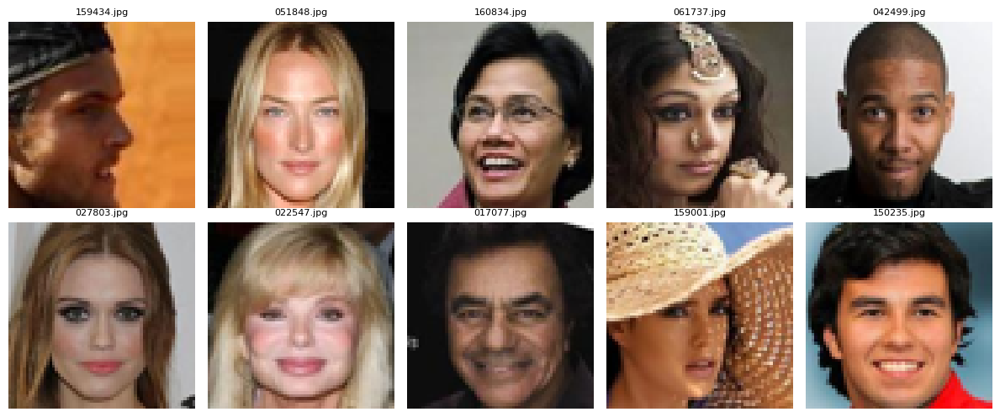

In [59]:
def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))


---

## **3. Encoder, decoder y autoencoder**

### Hipótesis del experimento

El modelo base usa `128` coordenadas latentes y esta variante usa `256`. La compresión pasa de `12288 / 128 = 96` valores de entrada por coordenada a `12288 / 256 = 48`, sin cambiar la resolución ni la profundidad de las capas convolucionales. Nuestra hipótesis es que `128` dimensiones no bastan para guardar la identidad, la textura y la geometría de una cara, y que ampliar el latente debería mejorar la reconstrucción. Si el FID y la pérdida mejoran de forma apreciable, concluiremos que el cuello de botella estaba parcialmente limitado por la dimensión latente.

Hay que tener en cuenta un matiz: esta prueba se entrena durante `30` épocas frente a las `60` del modelo base y usa una modificación del learning rate distinto (lo explicamos en la sección 4). Aun así, esas diferencias deberían perjudicar, o como mucho no favorecer, a esta variante en cuanto a tiempo de entrenamiento, por lo que una mejora clara es difícil de atribuir a otra cosa que no sea el latente.

In [60]:
encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="encoder_input")
x = encoder_inputs
for filters in (32, 64, 128, 256):
    x = layers.Conv2D(filters, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Flatten()(x)
z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector",
)(x)
encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()


Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 32, 32, 32)     │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_27 (LeakyReLU)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 16, 16, 64)     │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_28 (LeakyReLU)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 8, 8, 128)      │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_29 (LeakyReLU)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 4, 4, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_30 (LeakyReLU)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 256)            │     1,048,832 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,740,416 (6.64 MB)

 Trainable params: 1,739,456 (6.64 MB)

 Non-trainable params: 960 (3.75 KB)

In [61]:
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(4 * 4 * 256, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 256))(x)

for filters in (256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

decoder_outputs = layers.Conv2D(
    CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
)(x)
decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()


Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_31 (LeakyReLU)      │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_12 (UpSampling2D) │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_32 (LeakyReLU)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_13 (UpSampling2D) │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 16, 16, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_33 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_14 (UpSampling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 32, 32, 64)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_34 (LeakyReLU)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_15 (UpSampling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 64, 64, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_35 (LeakyReLU)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 2,044,643 (7.80 MB)

 Trainable params: 2,035,491 (7.76 MB)

 Non-trainable params: 9,152 (35.75 KB)

In [62]:
autoencoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="autoencoder_input")
autoencoder = keras.Model(
    autoencoder_input,
    decoder_ae(encoder_ae(autoencoder_input)),
    name="autoencoder",
)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 256)            │     1,740,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 3)      │     2,044,643 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,785,059 (14.44 MB)

 Trainable params: 3,774,947 (14.40 MB)

 Non-trainable params: 10,112 (39.50 KB)

---

## **4. Función de pérdida y optimización**

Mantenemos la misma pérdida que en `AE_complex1` para que la única diferencia relevante sea el tamaño del latente. La pérdida no garantiza por sí sola un morphing perfecto: la continuidad depende también de que el espacio latente sea suficientemente suave y de que las imágenes estén bien representadas.

Sí cambiamos la planificación de la tasa de aprendizaje. Sustituimos `ReduceLROnPlateau` por un **Cosine Decay** que baja suavemente de `1e-3` a `1e-5` a lo largo de las `30` épocas. Con menos épocas disponibles, preferimos una caída continua que garantice que el modelo termina con una tasa de aprendizaje pequeña y afina los detalles, en lugar de esperar a que la validación se estanque. `EarlyStopping` se mantiene.

In [63]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

INITIAL_LEARNING_RATE = 1e-3
MIN_LEARNING_RATE = 1e-5
DECAY_STEPS = int(np.ceil(len(x_train) / BATCH_SIZE) * EPOCHS)
learning_rate_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=INITIAL_LEARNING_RATE,
    decay_steps=DECAY_STEPS,
    alpha=MIN_LEARNING_RATE / INITIAL_LEARNING_RATE,
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate_schedule),
    loss=ssim_l1_loss,
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

---

## **5. Entrenamiento y guardado**

Con `TRAIN_MODEL = True` entrenamos usando únicamente `train` y validamos con `val` durante un máximo de `30` épocas; `test` queda reservado para la evaluación final. Guardamos el autoencoder, el encoder, el decoder y el historial para poder reproducir el resto del notebook sin reentrenar. Con `TRAIN_MODEL = False` cargamos esos artefactos ya calculados.

Los resultados muestran que el entrenamiento llegó a la última época (la mejor según `val_loss` es la `30`) y que la pérdida seguía mejorando al terminar, lo que indica que todavía había margen con más épocas. En comparación con `AE_complex1`, la `val_loss` baja de `0.1351` a `0.1077` y la pérdida de entrenamiento de `0.1251` a `0.1033`, pese a entrenar la mitad de épocas.

In [64]:
if TRAIN_MODEL:
    history_ae = autoencoder.fit(
        x_train,
        x_train,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_data=(x_val, x_val),
        callbacks=callbacks,
    )
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    HISTORY_PATH.write_text(json.dumps({
        key: [float(value) for value in values]
        for key, values in history_ae.history.items()
    }, indent=2))
else:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    autoencoder = keras.models.load_model(AE_PATH, custom_objects={"ssim_l1_loss": ssim_l1_loss})
    encoder_ae = keras.models.load_model(ENCODER_PATH)
    decoder_ae = keras.models.load_model(DECODER_PATH)
    history_ae = type("History", (), {"history": json.loads(HISTORY_PATH.read_text())})()


In [65]:
val_losses = history_ae.history["val_loss"]
best_index = int(np.argmin(val_losses))

print(f"Mejor época: {best_index + 1}")
print(f"Loss de entrenamiento: {history_ae.history['loss'][best_index]:.6f}")
print(f"Val loss: {val_losses[best_index]:.6f}")

Mejor época: 30
Loss de entrenamiento: 0.103345
Val loss: 0.107708


---

## **6. Reconstrucciones en test**

Antes de interpolar, comprobamos que el autoencoder conserva la identidad visual de imágenes que no usó para actualizar sus pesos. También representamos la evolución de la pérdida de entrenamiento y validación: una separación creciente entre ambas podría indicar *overfitting*. Aquí la separación es pequeña (`0.1033` frente a `0.1077`), por lo que no observamos sobreajuste relevante.

Después calculamos el **FID** de las reconstrucciones, que es la métrica que usaremos para comparar con `AE_complex1`.

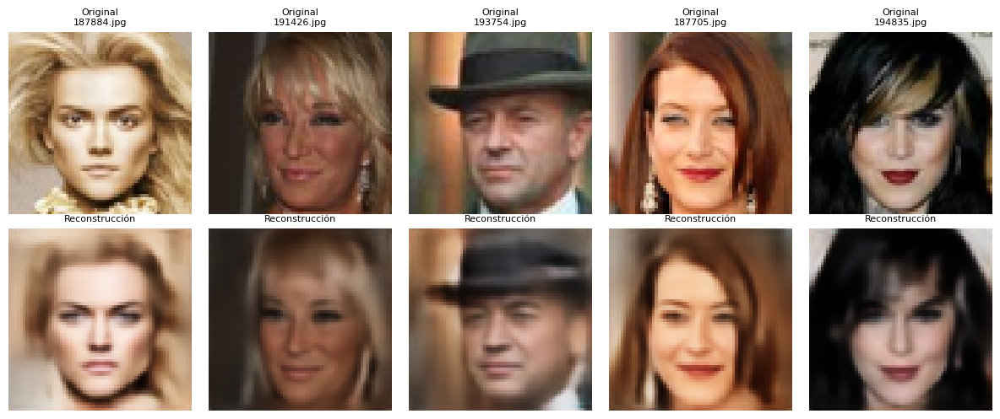

In [66]:
test_indices = sample_rng.choice(len(x_test), size=5, replace=False)
test_reconstructions = autoencoder.predict(x_test[test_indices], verbose=0)
comparison = np.concatenate([x_test[test_indices], test_reconstructions], axis=0)
titles = [f"Original\n{ids_test[i]}" for i in test_indices] + ["Reconstrucción"] * len(test_indices)
show_images(comparison, titles, cols=5, figsize=(12, 5))

Mejor época según val_loss: 30


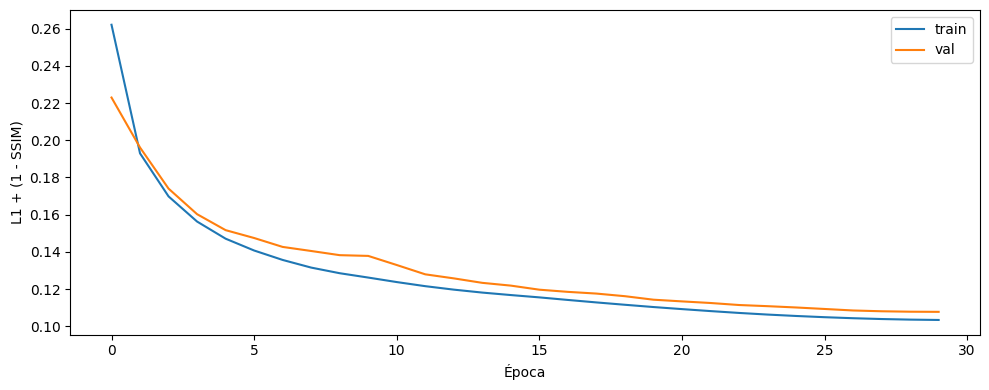

In [67]:
if hasattr(history_ae, "history") and "val_loss" in history_ae.history:
    best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
    print(f"Mejor época según val_loss: {best_epoch}")
    plt.figure(figsize=(10, 4))
    plt.plot(history_ae.history["loss"], label="train")
    plt.plot(history_ae.history["val_loss"], label="val")
    plt.xlabel("Época")
    plt.ylabel("L1 + (1 - SSIM)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [68]:
# FID de reconstrucciones y preparación para el FID del morphing
# El FID compara distribuciones de imágenes; por eso se usa un conjunto de test.
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_REAL_SAMPLES = min(1000, len(x_test))
FID_BATCH_SIZE = 32


def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se esperaban imágenes con forma (N, H, W, 1|3); recibidas {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    return float(fid.compute().item())

In [69]:
fid_reconstruction_images = x_test[:FID_REAL_SAMPLES]
fid_reconstruction_reference = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]
reconstructed_test_images = autoencoder.predict(
    fid_reconstruction_images,
    batch_size=FID_BATCH_SIZE,
    verbose=0,
)
reconstruction_fid = calculate_fid(
    reconstructed_test_images,
    fid_reconstruction_reference,
)
print(f"FID de reconstrucciones ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

FID de reconstrucciones (1000 imágenes): 63.6498


---

## **7. FID y morphing mediante interpolación en el espacio latente**

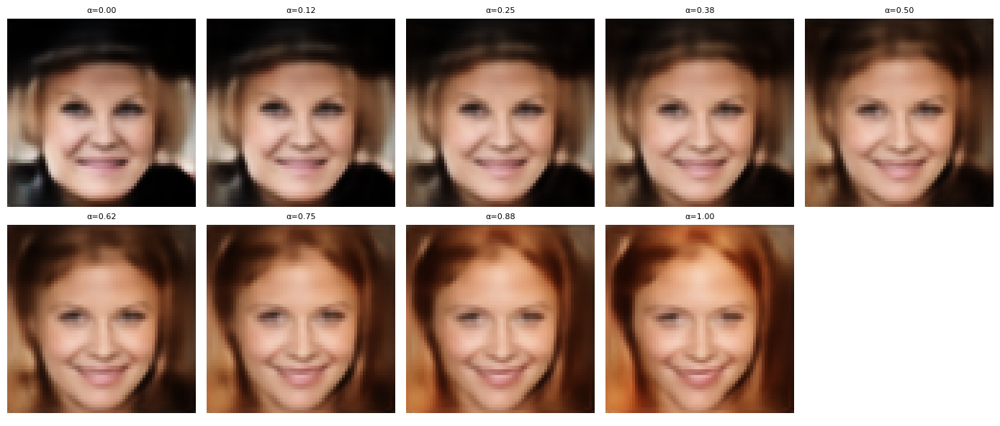

A: 182638.jpg | B: 182640.jpg


In [70]:
def morph_images(image_a, image_b, steps=9):
    if image_a.shape != image_b.shape:
        raise ValueError(f"Las imágenes deben tener la misma forma; recibidas {image_a.shape} y {image_b.shape}")
    z_a = encoder_ae.predict(image_a[None, ...], verbose=0)[0]
    z_b = encoder_ae.predict(image_b[None, ...], verbose=0)[0]
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)
    latent_path = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b
    return alphas, decoder_ae.predict(latent_path, verbose=0)

morph_a_index, morph_b_index = 0, 1
alphas, morph_sequence = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9)
show_images(
    morph_sequence,
    [f"α={alpha:.2f}" for alpha in alphas],
    cols=5,
    figsize=(14, 6),
)
print(f"A: {ids_test[morph_a_index]} | B: {ids_test[morph_b_index]}")

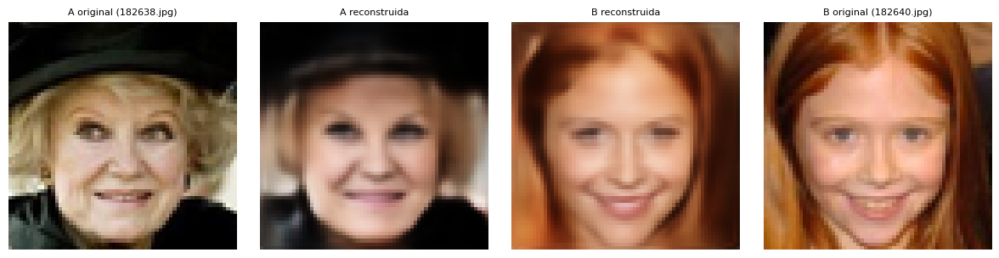

In [71]:
# Comparación de extremos: original frente a reconstrucción usada en la interpolación.
endpoints = np.stack([
    x_test[morph_a_index], morph_sequence[0],
    morph_sequence[-1], x_test[morph_b_index],
])
show_images(
    endpoints,
    [f"A original ({ids_test[morph_a_index]})", "A reconstruida", "B reconstruida", f"B original ({ids_test[morph_b_index]})"],
    cols=4,
    figsize=(12, 3),
)

---

## **8. Secuencia visual y GIF del morphing**

In [72]:
GIF_PATH = PROCESSED_DIR.parent.parent / "gif" / "fusion_ae1_latent256_morphing.gif"
N_FRAMES = 80
FRAME_MS = 50

z_a = encoder_ae.predict(
    x_test[morph_a_index][None, ...],
    verbose=0,
)[0]
z_b = encoder_ae.predict(
    x_test[morph_b_index][None, ...],
    verbose=0,
)[0]

alphas = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)
z_frames = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b

decoded = decoder_ae.predict(z_frames, verbose=0)

GIF guardado en '/Users/dani22/Desktop/ProyectoCD/morphing/gif/fusion_ae1_latent256_morphing.gif' | 80 fotogramas


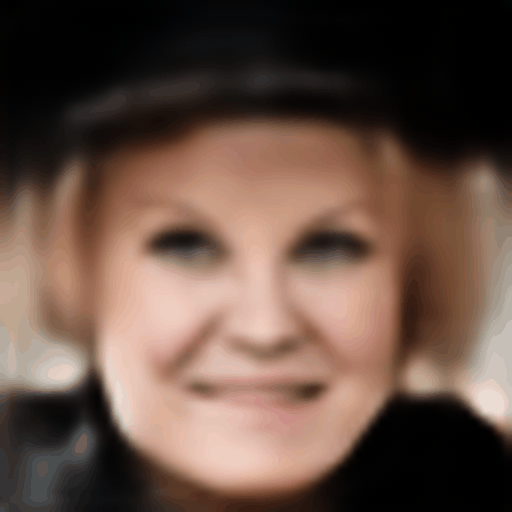

In [73]:
frames = [
    Image.fromarray((np.clip(image, 0, 1) * 255).astype(np.uint8))
    .resize((512, 512), Image.Resampling.BICUBIC)
    for image in decoded
]

gif_path = Path(GIF_PATH).resolve()
gif_path.parent.mkdir(parents=True, exist_ok=True)
if not frames:
    raise RuntimeError("No se generaron fotogramas para el GIF")

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=FRAME_MS,
    loop=0,
)

print(f"GIF guardado en '{gif_path}' | {len(frames)} fotogramas")
display(IPyImage(filename=str(gif_path)))

---

## **9. Decisiones de diseño y reflexión final**

En este notebook hemos querido aislar el efecto de una única variable, la dimensión del espacio latente. Las decisiones que hemos tomado son:

- **Duplicar el latente de `128` a `256` y mantener todo lo demás:** conservamos arquitectura, resolución, datos y pérdida para que la comparación con `AE_complex1` sea lo más limpia posible. Ampliar el latente reduce la compresión de `96` a `48` valores de entrada por coordenada y permite al decoder recibir más información sobre identidad, textura y geometría.

- **Mantener `L1 + (1 − SSIM)` como pérdida:** al no cambiarla, la mejora observada no puede explicarse por un objetivo de entrenamiento distinto.

- **Cosine Decay en lugar de `ReduceLROnPlateau`, y `30` épocas en lugar de `60`:** con un presupuesto de entrenamiento menor, una caída continua de la tasa de aprendizaje de `1e-3` a `1e-5` nos asegura un buen ajuste final. Reconocemos que este cambio, junto con el número de épocas, introduce una diferencia respecto al modelo base, por lo que la comparación no es estrictamente idéntica salvo en el latente. Sin embargo, no creemos que sea la causa principal de la mejora, ya que el modelo base entrenó el doble.

**Reflexión.** El FID de reconstrucción baja de `72.94` a `63.65` y la `val_loss` de `0.1351` a `0.1077`. Es una diferencia notable, y concluimos que con `128` dimensiones el latente era un cuello de botella real. No obstante, la mejora tiene límites. Un FID de `63.65` indica que las reconstrucciones han mejorado pero siguen perdiendo detalle, y seguir aumentando el latente tiene rendimientos decrecientes y reduce la presión para aprender una representación compacta (estamos usando cada vez más coordenadas para la representación por lo que comprimimos menos), lo que además puede empeorar la suavidad de la interpolación al ser el latente cada vez mas sparse. También observamos que el entrenamiento terminó en la última época, así que con más épocas probablemente mejoraría algo más. Por tanto, la dimensión latente era una limitación, pero no es la única: la capacidad y la forma del propio encoder y decoder también cuentan.

Como en el notebook anterior, no buscamos el modelo óptimo mediante una búsqueda exhaustiva, que es inviable con nuestra capacidad de cómputo, sino entender qué aporta cada decisión.

### Siguiente notebook: `AE_complex2.ipynb`

Una vez comprobado el efecto del latente, el siguiente paso es mejorar la red que lo produce y lo decodifica. En **`AE_complex2.ipynb`** incorporaremos **bloques residuales** al encoder y al decoder. Esperamos que esto mejore los resultados por varias razones:

- Una conexión residual suma la entrada del bloque a su salida, $y = x + F(x)$, de modo que cada bloque solo debe aprender una corrección. Esto facilita la optimización de redes más profundas y mejora el flujo del gradiente.
- Podemos añadir más capas y más capacidad en cada resolución sin que el entrenamiento se degrade, algo que con una pila secuencial de convoluciones es más difícil.
- Estas conexiones ayudan a conservar información de la imagen a través de la red, lo que debería recuperar detalles finos (bordes, textura) que ahora se pierden y que el FID penaliza.
- Un decoder con este flujo debería aprovechar mejor las `256` dimensiones del latente que acabamos de habilitar, en lugar de que el cuello de botella pase de ser el espacio latente a ser la capacidad del decoder.

Así, trabajaremos con el latente de `256` que hemos validado aquí y evaluaremos si el FID desciende con respecto a `63.65`.